# 03 · Training and comparing models

Four models, from dumbest to strongest. Each one learns from the **train** songs and is scored on the
**validation** songs it has never seen. The **test** songs stay locked until the very last cell.

In [1]:
import sys
import time
from pathlib import Path

sys.path.insert(0, "..")  # so we can import from src/

import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.data import FEATURES, get_xy, load_clean, split_tracks

df = load_clean(Path("..") / "data" / "spotify.db")
train, val, test = split_tracks(df)          # 70 / 15 / 15, tested in tests/test_data.py
X_train, y_train = get_xy(train)
X_val, y_val = get_xy(val)
len(train), len(val), len(test)

(53599, 11485, 11485)

## How we score a model

All three compare the model's guesses with the real popularity of the validation songs.

| Score | Plain meaning | Better is |
|---|---|---|
| **MAE** (mean absolute error) | On average, how many points off is each guess? A guess of 40 for a song at 50 is 10 off. | lower |
| **RMSE** (root mean squared error) | Like MAE, but big misses count extra. Missing by 30 hurts far more than three misses of 10. | lower |
| **R²** | What share of the ups and downs in popularity the model explains. 0 = no better than guessing the average, 1 = perfect. | higher |

MAE is the easiest to say out loud ("off by about 9 points on average"), so we'll lead with it.

In [2]:
def score(model, X, y):
    guess = model.predict(X)
    return {
        "MAE": mean_absolute_error(y, guess),
        "RMSE": mean_squared_error(y, guess) ** 0.5,
        "R2": r2_score(y, guess),
    }

results = {}

## 1. Baseline: always guess the average

The dumbest possible model. It ignores every feature and always guesses the average popularity of the train songs.
Every real model must beat this, or it has learned nothing.

In [3]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
results["Baseline (average)"] = score(baseline, X_val, y_val)
results["Baseline (average)"]

{'MAE': 14.88068405359417,
 'RMSE': 17.803945598183777,
 'R2': -8.176812807070277e-06}

## 2. Linear Regression: the best straight-line rule

It learns one weight per feature, like *popularity = 30 + 12 × danceability - 8 × instrumentalness + ...*

Two preparation steps it needs:
- **One-hot encoding** for genre: maths can't multiply the word "pop", so genre becomes 114 yes/no columns (`is_pop`, `is_rock`, ...).
- **Scaling**: `duration_ms` is in the hundreds of thousands while `energy` is 0 to 1. Scaling puts every number on a similar range so no feature dominates just because of its units.

A **pipeline** chains the preparation and the model, so the same steps always run in the same order.

In [4]:
numbers = [f for f in FEATURES if f != "track_genre"]

def prepare(scale):
    return ColumnTransformer([
        ("genre", OneHotEncoder(handle_unknown="ignore"), ["track_genre"]),
        ("numbers", StandardScaler() if scale else "passthrough", numbers),
    ])

linear = make_pipeline(prepare(scale=True), LinearRegression())
linear.fit(X_train, y_train)
results["Linear Regression"] = score(linear, X_val, y_val)
results["Linear Regression"]

{'MAE': 9.3523068331517, 'RMSE': 12.803423019754426, 'R2': 0.4828420285805124}

## 3. Random Forest: hundreds of trees vote

A **decision tree** asks yes/no questions: *Is the genre pop? Is energy above 0.8?* and ends at a guess.
A **forest** grows 200 trees, each on a random sample of the songs, and averages their guesses.
One tree makes odd mistakes; the average of many is steadier.

Trees can follow curves (like the energy hump in notebook 02), which straight lines can't.
Trees don't need scaling, because "energy above 0.8?" works the same in any unit. This one takes a minute or two.

In [5]:
start = time.time()
forest = make_pipeline(
    prepare(scale=False),
    RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=42),
)
forest.fit(X_train, y_train)
results["Random Forest"] = score(forest, X_val, y_val)
print(f"trained in {time.time() - start:.0f} seconds")
results["Random Forest"]

trained in 102 seconds


{'MAE': 8.813053888876675, 'RMSE': 12.354603391773301, 'R2': 0.518464122480603}

## 4. LightGBM: trees that fix each other's mistakes

Instead of independent trees voting, LightGBM builds trees **one after another**. Each new tree looks at where the
previous ones were wrong and tries to correct those errors. This is called **gradient boosting**, and it usually
wins on table-shaped data like ours.

It also understands categories directly, so genre doesn't need one-hot encoding.

- `n_estimators=600`: build 600 trees.
- `learning_rate=0.05`: each tree only corrects a small part of the error, which is slower but steadier.
- `num_leaves=63`: how many end points each tree may have (how detailed it can get).

In [6]:
start = time.time()
lgbm = LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, random_state=42, verbose=-1)
lgbm.fit(X_train, y_train)
results["LightGBM"] = score(lgbm, X_val, y_val)
print(f"trained in {time.time() - start:.0f} seconds")
results["LightGBM"]

trained in 2 seconds


{'MAE': 8.545615893307707,
 'RMSE': 12.232126927183964,
 'R2': 0.5279641410271083}

## Results on the validation songs

In [7]:
table = pd.DataFrame(results).T.round(3)
table

,MAE,RMSE,R2
Baseline (average),14.881,17.804,-0.000
Linear Regression,9.352,12.803,0.483
Random Forest,8.813,12.355,0.518
LightGBM,8.546,12.232,0.528


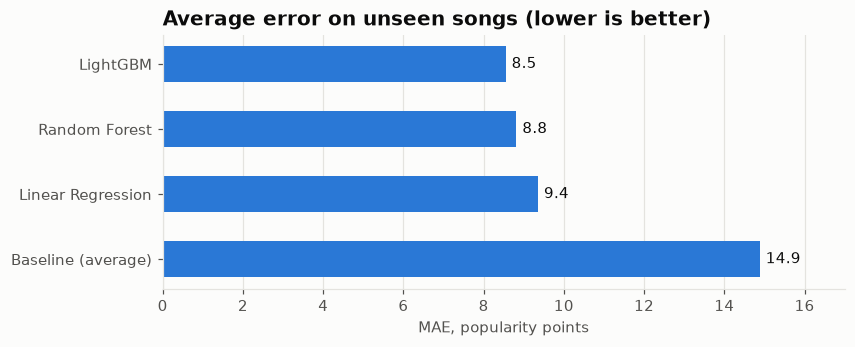

In [8]:
BLUE, INK, INK_2, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "xtick.color": INK_2, "ytick.color": INK_2, "axes.labelcolor": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})

order = table["MAE"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh(order.index, order.values, color=BLUE, height=0.55)
ax.bar_label(bars, labels=[f"{v:.1f}" for v in order.values], padding=4, color=INK, fontsize=10)
ax.set_title("Average error on unseen songs (lower is better)")
ax.set_xlabel("MAE, popularity points")
ax.set_xlim(0, 17)
ax.grid(axis="y", visible=False)
plt.show()

**How to read it:** guessing the average is off by about **15 points**. Every real model cuts that to about **9**,
so they all learned something real. LightGBM is best, but only **about 0.8 points** better than the straight line.

That's a genuine finding, not a disappointment: most of what can be predicted comes from **genre**, which even a
straight line handles well. The curves in the audio features (notebook 02) add a little on top, which is what the
trees capture. R² of about 0.53 means roughly half of what makes a song popular is **not** in this data at all:
the artist's fame, marketing, playlists, timing, luck.

## Overfitting check: train score versus validation score

**Overfitting** = memorising the homework instead of learning the subject. An overfit model scores far better on
songs it trained on than on new ones.

In [9]:
gap = pd.DataFrame({
    name: {"train MAE": score(model, X_train, y_train)["MAE"], "validation MAE": results[name]["MAE"]}
    for name, model in [("Linear Regression", linear), ("Random Forest", forest), ("LightGBM", lgbm)]
}).T.round(2)
gap["gap"] = (gap["validation MAE"] - gap["train MAE"]).round(2)
gap

,train MAE,validation MAE,gap
Linear Regression,9.22,9.35,0.13
Random Forest,4.51,8.81,4.30
LightGBM,6.40,8.55,2.15


The straight line scores about the same on both, because it's too simple to memorise.
Random Forest is off by only ~4.5 on its own train songs but ~8.8 on new ones: it memorised a lot.
LightGBM sits in between and still scores best on unseen songs, which is the number that counts.

## Final exam: the test songs, used once

We chose LightGBM using the validation songs. Now, and only now, we score it on the locked test songs.
This is the number for the README. We don't go back and tweak the model after seeing it,
or the test songs stop being unseen.

In [10]:
X_test, y_test = get_xy(test)
final = pd.DataFrame({
    "LightGBM on test": score(lgbm, X_test, y_test),
    "Baseline on test": score(baseline, X_test, y_test),
}).T.round(3)
final

,MAE,RMSE,R2
LightGBM on test,8.452,12.169,0.535
Baseline on test,14.853,17.852,-0.000
